In [6]:
#Part 1
import numpy as np

def f(x):
    return np.exp(x - np.sqrt(x))- x

def dx_f(x):
    return np.exp(x - np.sqrt(x)) * (1 - 1/(2*np.sqrt(x))) - 1

def newton_bisection(f, fp, x0, x1, kmax=200, tol=1.e-10, verbose=False):
    """
    Finds a root of f between x0 and x1.
    Each step: try a Newton step. If the new estimate falls
    outside the bracketing interval [x0, x1], do a bisection step instead.
    Returns the roor and the number of the iterations used.
    """
    f0 = f(x0)
    f1 = f(x1)

    if f0*f1 > 0:
        print("Error: The Interval Does Not Bracket A Root")
        return None, 0
    if f0 == 0:
        return x0, 0
    if f1 == 0:
        return x1, 0

    x = (x0 + x1)/2.0

    for k in range(1, kmax):
        fx = f(x)

        if fx == 0:
            return x, k

        if f0*fx < 0:
            x1 = x
        else:
            x0, f0 = x, fx

        dfx = fp(x) #Newton Step
        if dfx != 0:
            xnew = x - fx/dfx
        else:
            xnew = x0 - 1.0

        if xnew <= x0 or xnew >= x1:
            xnew = (x0 + x1)/2.0
            method = "bisection"
        else:
            method = "newton"

        xdiff = abs(xnew - x)
        if verbose:
            print(k, method, xnew, xdiff, abs(f(xnew)))

        if xdiff < tol:
            return xnew, k #termination criterion (s.t., successive estimates are close)

        x = xnew

    print("Warning: Max Number of Iterations Reached")
    return None, kmax #For unsuccessful convergence

#Test on both roots
print("Looking for the root near x = 1 (interval 0 to 1.5):")
root1, n1 = newton_bisection(f, dx_f, 0.0, 1.5, verbose=True)
print("root 1=", root1, " f(root) =", f(root1), " iterations =", n1)

print("")
print("Looking for the root near x = 2.5 (interval 1.5 to 3):")
root2, n2 = newton_bisection(f, dx_f, 1.5, 3.0, verbose=True)
print("root 2=", root2, " f(root) =", f(root2), " iterations =", n2)

print("")
print("Test where the bisection fallback is needed (interval 0.8 to 2.4:")
root3, n3 = newton_bisection(f, dx_f, 0.8, 2.4, verbose=True)
print("root 3 =", root3, " f(root)", f(root3), " iterations =", n3)

Looking for the root near x = 1 (interval 0 to 1.5):
1 newton 0.9752104568011606 0.22521045680116059 0.012548097537693259
2 newton 0.9997013133712656 0.02449085657010497 0.00014936561723788433
3 newton 0.9999999554086861 0.00029864203742058226 2.2295657431392613e-08
4 newton 0.999999999999999 4.459131286438378e-08 5.551115123125783e-16
5 newton 1.0 9.992007221626409e-16 0.0
root 1= 1.0  f(root) = 0.0  iterations = 5

Looking for the root near x = 2.5 (interval 1.5 to 3):
1 newton 2.5733386867252306 0.3233386867252306 0.06243237630596665
2 newton 2.496662111813474 0.07667657491175639 0.004059080540349758
3 newton 2.490940223436726 0.00572188837674803 2.1690143949815166e-05
4 newton 2.490909317845007 3.0905591719143644e-05 6.30914431809515e-10
5 newton 2.490909316945985 8.990221900262441e-10 0.0
root 2= 2.490909316945985  f(root) = 0.0  iterations = 6

Test where the bisection fallback is needed (interval 0.8 to 2.4:
1 bisection 1.2000000000000002 0.3999999999999999 0.08978367359433581
2

wt = 1.0  psi= 1.0141790871647136  iterations = 4


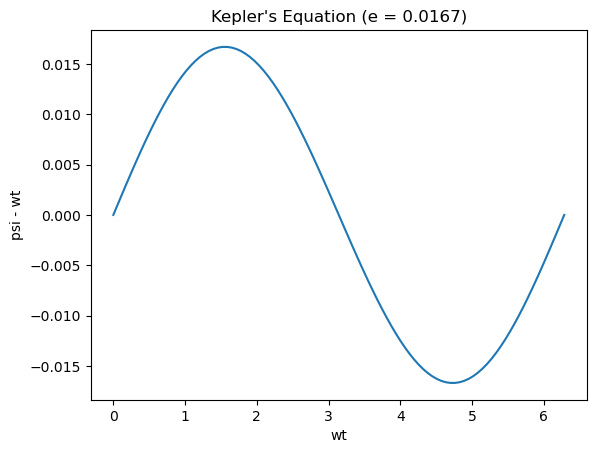

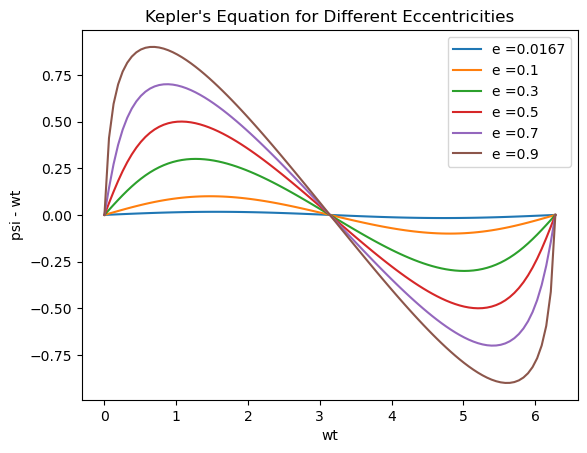

In [9]:
#Part 2
import numpy as np
import matplotlib.pyplot as plt

e = 0.0167
wt = 0.0

def g(psi):
    return psi - e*np.sin(psi) - wt

def dx_g(psi):
    return 1 - e*np.cos(psi)

#2a.)
wt = 1.0
psi, n = newton_bisection(g, dx_g, 0.0, 2*np.pi)
print("wt =", wt, " psi=", psi, " iterations =", n)

wt_values = np.linspace(0, 2*np.pi, 100)

diff = []
for wt in wt_values:
    psi, n = newton_bisection(g, dx_g, 0.0, 2*np.pi)
    diff.append(psi - wt)

#2b.)
plt.plot(wt_values, diff)
plt.xlabel("wt")
plt.ylabel("psi - wt")
plt.title("Kepler's Equation (e = 0.0167)")
plt.show()

#2c.)
e_list = [0.0167, 0.1, 0.3, 0.5, 0.7, 0.9]

for e in e_list:
    diff = []
    for wt in wt_values:
        psi, n = newton_bisection(g, dx_g, 0.0, 2*np.pi)
        diff.append(psi - wt)
    plt.plot(wt_values, diff, label="e =" + str(e))

plt.xlabel("wt")
plt.ylabel("psi - wt")
plt.title("Kepler's Equation for Different Eccentricities")
plt.legend()
plt.show()